# 05 - Interprétation des segments

Objectif : décrire les 3 segments (CAH Ward, k = 3) et proposer une action marketing pour chacun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

import sys
sys.path.insert(0, "..")
import fonctions

X, y, Xa, Xb = fonctions.preparer()

clients = X.copy()
clients["segment"] = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xa)   # solution retenue au notebook 04
clients["souscrit"] = y                                                   # la cible sert ici pour interpréter

## 1. Taille et taux de souscription

On appelle les segments S1, S2, S3, du plus faible au plus fort taux de souscription.

In [2]:
taux = clients.groupby("segment")["souscrit"].mean()
ordre = taux.sort_values().index      # du plus faible au plus fort

noms = {}
for i in range(len(ordre)):
    noms[ordre[i]] = "S" + str(i + 1)
clients["segment"] = clients["segment"].map(noms)

resume = pd.DataFrame()
resume["clients"] = clients.groupby("segment").size()
resume["part (%)"] = (resume["clients"] / len(clients) * 100).round(1)
resume["souscription (%)"] = (clients.groupby("segment")["souscrit"].mean() * 100).round(1)
print("Taux global :", round(y.mean() * 100, 1), "%")
resume

Taux global : 11.3 %


,clients,part (%),souscription (%)
segment,,,
S1,2617,65.4,5.1
S2,1126,28.2,18.7
S3,257,6.4,41.6


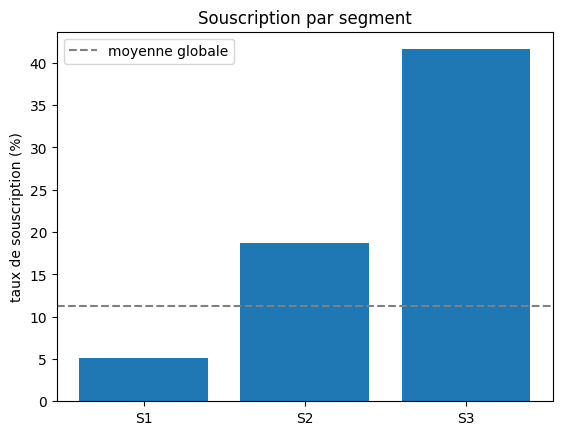

In [3]:
plt.bar(resume.index, resume["souscription (%)"])
plt.axhline(y.mean() * 100, color="gray", linestyle="--", label="moyenne globale")
plt.ylabel("taux de souscription (%)")
plt.title("Souscription par segment")
plt.legend()
plt.show()

## 2. Moyennes des variables numériques

In [4]:
numeriques = ["age", "campaign", "previous", "cons.price.idx", "cons.conf.idx", "euribor3m"]
moyennes = clients.groupby("segment")[numeriques].mean().round(2)
moyennes

,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m
segment,,,,,,
S1,40.34,2.65,0.00,93.85,-39.40,4.82
S2,38.24,2.08,0.51,93.12,-45.08,1.47
S3,47.22,1.82,0.60,92.55,-31.48,0.81


## 3. Modalité la plus fréquente (mode) des variables catégorielles

In [5]:
categorielles = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
modes = pd.DataFrame()
for c in categorielles:
    modes[c] = clients.groupby("segment")[c].agg(pd.Series.mode)
modes

,job,marital,education,default,housing,loan,contact,poutcome
segment,,,,,,,,
S1,admin.,married,university.degree,no,yes,no,cellular,nonexistent
S2,blue-collar,married,university.degree,no,yes,no,cellular,nonexistent
S3,admin.,married,university.degree,no,yes,no,cellular,nonexistent


## 4. Quelques pourcentages utiles

In [6]:
# pourcentage de chaque modalité dans chaque segment
print((pd.crosstab(clients["segment"], clients["poutcome"], normalize="index") * 100).round(1), "\n")
print((pd.crosstab(clients["segment"], clients["contact"], normalize="index") * 100).round(1), "\n")
print((pd.crosstab(clients["segment"], clients["marital"], normalize="index") * 100).round(1))

poutcome  failure  nonexistent  success
segment                                
S1            0.0        100.0      0.0
S2           31.6         60.5      7.9
S3           32.3         51.8     16.0 

contact  cellular  telephone
segment                     
S1           50.4       49.6
S2           91.6        8.4
S3           88.7       11.3 

marital  divorced  married  single  unknown
segment                                    
S1           10.4     64.1    25.4      0.2
S2           10.3     52.1    37.0      0.5
S3           14.0     57.2    28.4      0.4


In [7]:
clients["retraite"] = clients["job"] == "retired"
clients["plus_de_60_ans"] = clients["age"] >= 60
clients["universite"] = clients["education"] == "university.degree"
clients["default_inconnu"] = clients["default"] == "unknown"

parts = clients.groupby("segment")[["retraite", "plus_de_60_ans", "universite", "default_inconnu"]].mean() * 100
parts.round(1)

,retraite,plus_de_60_ans,universite,default_inconnu
segment,,,,
S1,3.0,0.9,29.1,25.6
S2,3.3,2.7,27.7,13.1
S3,21.8,27.6,38.1,4.3


## 5. Radar des segments

Chaque axe est ramené entre 0 (plus petite valeur des 3 segments) et 1 (plus grande).

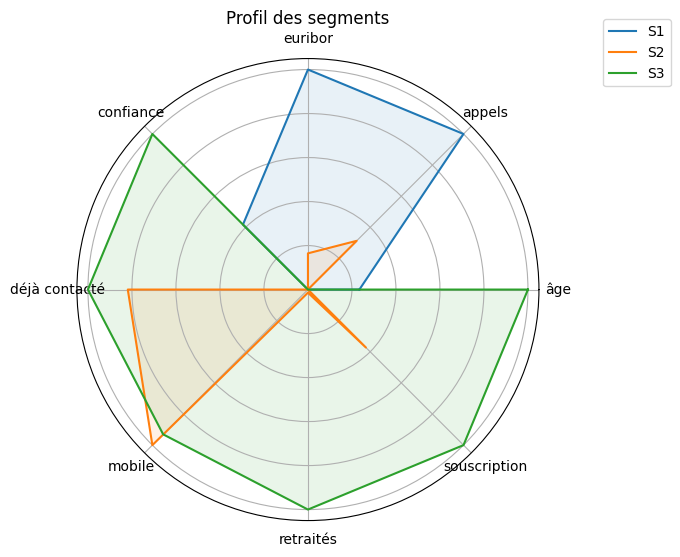

In [8]:
radar = pd.DataFrame()
radar["âge"] = moyennes["age"]
radar["appels"] = moyennes["campaign"]
radar["euribor"] = moyennes["euribor3m"]
radar["confiance"] = moyennes["cons.conf.idx"]
radar["déjà contacté"] = 100 - pd.crosstab(clients["segment"], clients["poutcome"], normalize="index")["nonexistent"] * 100
radar["mobile"] = pd.crosstab(clients["segment"], clients["contact"], normalize="index")["cellular"] * 100
radar["retraités"] = parts["retraite"]
radar["souscription"] = resume["souscription (%)"]

radar = (radar - radar.min()) / (radar.max() - radar.min())   # entre 0 et 1

angles = np.linspace(0, 2 * np.pi, len(radar.columns), endpoint=False)
angles = np.append(angles, angles[0])     # on referme le polygone

plt.figure(figsize=(6, 6))
ax = plt.subplot(polar=True)
for segment in radar.index:
    valeurs = np.append(radar.loc[segment].values, radar.loc[segment].values[0])
    ax.plot(angles, valeurs, label=segment)
    ax.fill(angles, valeurs, alpha=0.1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar.columns)
ax.set_yticklabels([])
plt.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.title("Profil des segments")
plt.show()

## 6. Portraits et recommandations

| Segment | Portrait | Recommandation |
|---|---|---|
| S1 : prospects froids | Jamais contactés avant, appelés quand les taux étaient hauts (euribor environ 4,8), moitié sur téléphone fixe. Souscription la plus faible. | Réduire le coût : moins d'appels, passer au mobile ou au SMS / e-mail, appeler quand les taux baissent. |
| S2 : clients relancés | Un peu plus jeunes, plus souvent célibataires, joints sur mobile. 4 sur 10 ont déjà été contactés avant. Souscription au-dessus de la moyenne. | Relancer en priorité les clients déjà intéressés, sur mobile, avec un message court sur la sécurité de l'épargne. |
| S3 : seniors épargnants | Les plus âgés (beaucoup de retraités et de diplômés), appelés quand les taux étaient bas et la confiance haute. Souscription la plus forte. | Priorité absolue : conseiller dédié et offre de dépôt à terme pour la retraite. Ils sont peu nombreux, on peut tous les appeler. |

## 7. Limite

Les variables économiques (euribor3m, cons.conf.idx) sont les mêmes pour tous les clients appelés le même jour. Les segments mélangent donc le profil du client et le moment de l'appel.